In [1]:
import sys
import inspect

from pathlib import Path

ML_DIR = Path(r"D:\FloodVision-AI\ml")

SRC_DIR = ML_DIR / "src"

PRODUCTION_DIR = (
    ML_DIR / "artifacts" / "production"
)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

assert PRODUCTION_DIR.is_dir()

print("ML directory:", ML_DIR)
print("Production bundle:", PRODUCTION_DIR)

print("\nPipeline environment initialized!")

ML directory: D:\FloodVision-AI\ml
Production bundle: D:\FloodVision-AI\ml\artifacts\production

Pipeline environment initialized!


In [2]:
import importlib

modules = [
    "model_loader",
    "schemas",
    "preprocessor",
    "predictor",
    "postprocessor",
    "tiling",
    "geospatial",
    "raster_exporter",
    "area_analyzer",
    "vectorizer",
    "geometry_processor",
    "vector_exporter"
]

for module_name in modules:

    module = importlib.import_module(
        f"floodvision.inference.{module_name}"
    )

    print("\n" + "=" * 65)
    print("MODULE:", module_name)
    print("=" * 65)

    for name, cls in inspect.getmembers(
        module,
        inspect.isclass
    ):

        if cls.__module__ != module.__name__:
            continue

        print(
            f"\n{name}{inspect.signature(cls)}"
        )

        for method_name, method in inspect.getmembers(
            cls,
            inspect.isfunction
        ):

            if method_name.startswith("_"):
                continue

            print(
                f"  {method_name}"
                f"{inspect.signature(method)}"
            )

print("\nModule interface inspection completed!")


MODULE: model_loader

ModelLoader(bundle_dir)
  calculate_sha256(file_path)
  get_model_info(self)
  load(self, device='auto')
  resolve_device(device='auto')
  validate_artifact(self, artifact)
  verify_integrity(self)

MODULE: schemas

PredictionResult(mask: numpy.ndarray, probabilities: numpy.ndarray, valid_mask: numpy.ndarray, metadata: floodvision.inference.schemas.RasterMetadata, statistics: floodvision.inference.schemas.PredictionStatistics, model_version: str, threshold: float, device: str, inference_time_ms: float, postprocessing_time_ms: float) -> None
  to_summary(self) -> dict

PredictionStatistics(total_pixels: int, valid_pixels: int, invalid_pixels: int, water_pixels: int, non_water_pixels: int, water_coverage: float, non_water_coverage: float, valid_percentage: float, mean_water_probability: float) -> None

PreprocessedInput(tensor: torch.Tensor, valid_mask: numpy.ndarray, metadata: floodvision.inference.schemas.RasterMetadata) -> None

RasterMetadata(path: pathlib.Path

In [3]:
from floodvision.inference.pipeline_config import (
    PipelineConfig
)

import json

config = PipelineConfig(
    device="cpu"
)

print("=" * 60)
print("PRODUCTION PIPELINE CONFIGURATION")
print("=" * 60)

print(
    json.dumps(
        config.to_dict(),
        indent=4
    )
)

print("\nPipeline configuration initialized!")

PRODUCTION PIPELINE CONFIGURATION
{
    "device": "cpu",
    "require_crs": true,
    "allow_unverified_band_order": false,
    "tile_size": 512,
    "overlap": 128,
    "min_blend_weight": 0.001,
    "storage": "auto",
    "memory_budget_mib": 128,
    "max_pixels": 100000000,
    "max_tiles": 1000,
    "connectivity": 4,
    "max_vector_pixels": 4000000,
    "max_regions": 100000,
    "simplification_tolerance_m": 5.0,
    "max_area_change_percentage": 1.0,
    "min_geometry_iou": 1.0,
    "max_invalid_encroachment": 0,
    "raster_block_size": 256,
    "work_dir": null
}

Pipeline configuration initialized!


In [4]:
tiling_config = config.get_tiling_config()

assert tiling_config.tile_size == 512
assert tiling_config.overlap == 128

assert (
    tiling_config.min_blend_weight
    == 0.001
)

print("Tile size:", tiling_config.tile_size)
print("Overlap:", tiling_config.overlap)

print(
    "Stride:",
    tiling_config.tile_size -
    tiling_config.overlap
)

print("\nTiling configuration compatibility PASSED!")

Tile size: 512
Overlap: 128
Stride: 384

Tiling configuration compatibility PASSED!


In [5]:
from floodvision.inference.exceptions import (
    InputValidationError
)

invalid_configs = [

    ("Incorrect tile size",
     {"tile_size": 256}),

    ("Invalid overlap",
     {"overlap": 512}),

    ("Negative overlap",
     {"overlap": -1}),

    ("Invalid blending weight",
     {"min_blend_weight": 0}),

    ("NaN blending weight",
     {"min_blend_weight": float("nan")}),

    ("Unsupported storage",
     {"storage": "unknown"}),

    ("Invalid memory budget",
     {"memory_budget_mib": 0}),

    ("Invalid pixel limit",
     {"max_pixels": -1}),

    ("Invalid connectivity",
     {"connectivity": 6}),

    ("Negative tolerance",
     {"simplification_tolerance_m": -5}),

    ("Invalid area change",
     {"max_area_change_percentage": 101}),

    ("Invalid geometry IoU",
     {"min_geometry_iou": 1.5}),

    ("Invalid encroachment",
     {"max_invalid_encroachment": 1}),

    ("Invalid raster block size",
     {"raster_block_size": 250})
]

for name, kwargs in invalid_configs:

    try:

        PipelineConfig(**kwargs)

    except InputValidationError as error:

        print(f"[PASS] {name}")
        print(f"Reason: {error}\n")

    else:

        raise AssertionError(
            f"Validation failed: {name}"
        )

print("All configuration rejection tests PASSED!")

[PASS] Incorrect tile size
Reason: Production model requires 512 x 512 tiles.

[PASS] Invalid overlap
Reason: Invalid tile overlap.

[PASS] Negative overlap
Reason: Invalid tile overlap.

[PASS] Invalid blending weight
Reason: Invalid minimum blending weight.

[PASS] NaN blending weight
Reason: Invalid minimum blending weight.

[PASS] Unsupported storage
Reason: Unsupported storage mode.

[PASS] Invalid memory budget
Reason: memory_budget_mib must be positive.

[PASS] Invalid pixel limit
Reason: max_pixels must be positive.

[PASS] Invalid connectivity
Reason: Connectivity must be 4 or 8.

[PASS] Negative tolerance
Reason: Invalid simplification tolerance.

[PASS] Invalid area change
Reason: Invalid maximum area change.

[PASS] Invalid geometry IoU
Reason: Invalid minimum geometry IoU.

[PASS] Invalid encroachment
Reason: Invalid pixel encroachment is not allowed.

[PASS] Invalid raster block size
Reason: Raster block size must be a positive multiple of 16.

All configuration rejection

In [6]:
from floodvision.inference.pipeline_result import (
    PipelineResult,
    ArtifactInfo
)

result = PipelineResult(

    analysis_id="validation_001",

    source_file="synthetic_sar.tif",

    model_version="1.0.0",

    device="cpu",

    threshold=0.5,

    output_dir=ML_DIR / "artifacts" / "pipeline_validation",

    geospatial_metadata={
        "width": 512,
        "height": 512,
        "crs": "EPSG:4326"
    },

    statistics={
        "total_pixels": 262144,
        "valid_pixels": 262144,
        "invalid_pixels": 0,
        "water_pixels": 65536,
        "non_water_pixels": 196608,
        "water_coverage": 25.0
    },

    tiling={
        "tile_size": 512,
        "overlap": 128,
        "total_tiles": 1,
        "processed_tiles": 1,
        "skipped_tiles": 0
    },

    timing={
        "inference_ms": 150.0,
        "processing_ms": 350.0
    },

    area_analytics={
        "water_area_km2": 6.4
    }
)

print(result.to_json())

print("\nStructured pipeline result PASSED!")

{
    "project": "FloodVision AI",
    "analysis_id": "validation_001",
    "status": "completed",
    "task": "binary_water_segmentation",
    "deployment_status": "research_prototype",
    "source_file": "synthetic_sar.tif",
    "model": {
        "version": "1.0.0",
        "device": "cpu",
        "threshold": 0.5
    },
    "geospatial_metadata": {
        "width": 512,
        "height": 512,
        "crs": "EPSG:4326"
    },
    "statistics": {
        "total_pixels": 262144,
        "valid_pixels": 262144,
        "invalid_pixels": 0,
        "water_pixels": 65536,
        "non_water_pixels": 196608,
        "water_coverage": 25.0
    },
    "tiling": {
        "tile_size": 512,
        "overlap": 128,
        "total_tiles": 1,
        "processed_tiles": 1,
        "skipped_tiles": 0
    },
    "area_analytics": {
        "water_area_km2": 6.4
    },
    "vectorization": null,
    "geometry_processing": null,
    "geometry_fidelity": null,
    "timing": {
        "inference_ms":

In [7]:
serialized = result.to_json()

decoded = json.loads(serialized)

assert decoded["analysis_id"] == "validation_001"

assert decoded["model"]["version"] == "1.0.0"

assert result.water_coverage == 25.0

assert result.water_area_km2 == 6.4

assert result.processing_time_ms == 350.0

assert decoded["vectorization"] is None

assert decoded["geometry_processing"] is None

print("[PASS] JSON serialization")
print("[PASS] Model metadata")
print("[PASS] Water coverage property")
print("[PASS] Geographical area property")
print("[PASS] Processing time property")
print("[PASS] Optional result fields")

print("\nPipeline result validation PASSED!")

[PASS] JSON serialization
[PASS] Model metadata
[PASS] Water coverage property
[PASS] Geographical area property
[PASS] Processing time property
[PASS] Optional result fields

Pipeline result validation PASSED!


In [8]:
import importlib
import inspect

inference_dir = (
    SRC_DIR /
    "floodvision" /
    "inference"
)

for path in sorted(inference_dir.glob("*.py")):

    if path.stem.startswith("_"):
        continue

    module = importlib.import_module(
        f"floodvision.inference.{path.stem}"
    )

    for name, cls in inspect.getmembers(
        module,
        inspect.isclass
    ):

        if cls.__module__ != module.__name__:
            continue

        if not any(
            keyword in name.lower()
            for keyword in (
                "engine",
                "accumulator",
                "tiled",
                "reader"
            )
        ):
            continue

        print("\nMODULE:", path.stem)

        print(
            f"{name}{inspect.signature(cls)}"
        )

        for method_name, method in inspect.getmembers(
            cls,
            inspect.isfunction
        ):

            if method_name.startswith("_"):
                continue

            print(
                f"  {method_name}"
                f"{inspect.signature(method)}"
            )

print("\nRemaining interface inspection completed!")


MODULE: accumulator
WeightedProbabilityAccumulator(height: int, width: int, storage: str = 'memory', work_dir: str | pathlib.Path | None = None)
  add(self, window: floodvision.inference.tiling.TileWindow, probabilities: numpy.ndarray, valid_mask: numpy.ndarray, weights: numpy.ndarray)
  close(self)
  finalize(self, threshold: float = 0.5, chunk_rows: int = 256)
  flush(self)

MODULE: tile_reader
RasterTileReader(config: floodvision.inference.tiling.TilingConfig | None = None, require_crs: bool = True, allow_unverified_band_order: bool = False)
  count_tiles(self, path: str | pathlib.Path) -> int
  get_metadata(self, path: str | pathlib.Path) -> floodvision.inference.schemas.RasterMetadata
  iter_tiles(self, path: str | pathlib.Path) -> Iterator[floodvision.inference.tile_reader.RasterTile]
  read_window(self, src, metadata: floodvision.inference.schemas.RasterMetadata, window: floodvision.inference.tiling.TileWindow) -> floodvision.inference.tile_reader.RasterTile

MODULE: tiled_pred

In [11]:
import tempfile

from floodvision.inference.artifact_manager import (
    ArtifactManager
)

TEST_DIR = Path(
    tempfile.mkdtemp(
        prefix="floodvision_pipeline_"
    )
)

artifact_test_dir = TEST_DIR / "artifact_test"

with ArtifactManager(artifact_test_dir) as manager:

    manager.write_json(
        "test.json",
        {"status": "success"}
    )

    artifact = manager.register(
        "test",
        "test.json"
    )

    assert manager.verify()

    manager.write_manifest(
        "test_analysis"
    )

    manager.commit()

assert (artifact_test_dir / "test.json").is_file()

assert (artifact_test_dir / "manifest.json").is_file()

print("[PASS] Artifact registration")
print("[PASS] SHA-256 verification")
print("[PASS] Manifest generation")
print("[PASS] Directory publication")

print("\nArtifact manager PASSED!")

[PASS] Artifact registration
[PASS] SHA-256 verification
[PASS] Manifest generation
[PASS] Directory publication

Artifact manager PASSED!


In [12]:
failed_output = TEST_DIR / "failed_analysis"

staging_path = None

try:

    with ArtifactManager(failed_output) as manager:

        staging_path = manager.staging_dir

        manager.write_json(
            "temporary.json",
            {"status": "processing"}
        )

        raise RuntimeError(
            "Simulated processing failure"
        )

except RuntimeError:

    pass

assert not failed_output.exists()

assert not staging_path.exists()

print("[PASS] Incomplete output protection")
print("[PASS] Temporary directory cleanup")

print("\nFailure cleanup PASSED!")

[PASS] Incomplete output protection
[PASS] Temporary directory cleanup

Failure cleanup PASSED!


In [17]:
import importlib
from pathlib import Path

module_classes = {
    "pipeline_config": "PipelineConfig",
    "pipeline_result": "PipelineResult",
    "artifact_manager": "ArtifactManager",
    "geometry_fidelity": "GeometryFidelityValidator",
    "pipeline": "FloodInferencePipeline"
}

importlib.invalidate_caches()

for name, class_name in module_classes.items():

    path = (
        ML_DIR / "src/floodvision/inference" / f"{name}.py"
    )

    source = path.read_text(encoding="utf-8")

    assert f"class {class_name}" in source, (
        f"{class_name} missing from {path}"
    )

    module = importlib.import_module(
        f"floodvision.inference.{name}"
    )

    module = importlib.reload(module)

    assert hasattr(module, class_name), (
        f"Class import failed: {class_name}"
    )

    print(f"[PASS] {name} -> {class_name}")

print("\nAll pipeline modules verified!")

[PASS] pipeline_config -> PipelineConfig
[PASS] pipeline_result -> PipelineResult
[PASS] artifact_manager -> ArtifactManager
[PASS] geometry_fidelity -> GeometryFidelityValidator
[PASS] pipeline -> FloodInferencePipeline

All pipeline modules verified!


In [19]:
from floodvision.inference.pipeline_config import PipelineConfig
from floodvision.inference.pipeline import FloodInferencePipeline
from floodvision.inference.artifact_manager import ArtifactManager

config = PipelineConfig(device="cpu")

pipeline = FloodInferencePipeline(
    bundle_dir=PRODUCTION_DIR,
    config=config
)

print(
    json.dumps(
        pipeline.get_model_info(),
        indent=4
    )
)

print("\nUnified pipeline initialized!")

{
    "model_name": "MobileNetV3 U-Net",
    "model_version": "1.0.0",
    "device": "cpu",
    "parameters": 1034057,
    "trainable_parameters": 0,
    "training_mode": false,
    "threshold": 0.5,
    "input_bands": [
        "VV",
        "VH"
    ],
    "tile_height": 512,
    "tile_width": 512,
    "status": "ready"
}

Unified pipeline initialized!


In [20]:
from floodvision.inference.pipeline import (
    FloodInferencePipeline
)

pipeline = FloodInferencePipeline(
    bundle_dir=PRODUCTION_DIR,
    config=config
)

print(
    json.dumps(
        pipeline.get_model_info(),
        indent=4
    )
)

print("\nUnified pipeline initialized!")

{
    "model_name": "MobileNetV3 U-Net",
    "model_version": "1.0.0",
    "device": "cpu",
    "parameters": 1034057,
    "trainable_parameters": 0,
    "training_mode": false,
    "threshold": 0.5,
    "input_bands": [
        "VV",
        "VH"
    ],
    "tile_height": 512,
    "tile_width": 512,
    "status": "ready"
}

Unified pipeline initialized!


In [14]:
import pandas as pd
import yaml

with open(
    ML_DIR / "configs/dataset.yaml",
    encoding="utf-8"
) as file:

    dataset_config = yaml.safe_load(file)["dataset"]

val_samples = pd.read_csv(
    ML_DIR /
    "data/splits/geographical/val.csv"
)

sample_id = val_samples.iloc[0]["sample_id"]

sample_path = (
    ML_DIR /
    dataset_config["root_dir"] /
    dataset_config["image_dir"] /
    f"{sample_id}_S1Hand.tif"
)

assert sample_path.is_file()

print("Sample:", sample_id)
print("Input:", sample_path)

print("\nSatellite input ready!")

Sample: Mekong_1111068
Input: D:\FloodVision-AI\ml\data\raw\Sen1Floods11\S1Hand\Mekong_1111068_S1Hand.tif

Satellite input ready!


In [21]:
import uuid

output_dir = (
    ML_DIR /
    "artifacts" /
    "pipeline_validation" /
    f"analysis_{uuid.uuid4().hex[:12]}"
)

result = pipeline.predict(
    input_path=sample_path,
    output_dir=output_dir,
    export_rasters=True,
    export_vectors=True,
    calculate_area=True
)

print(result.to_json())

print("\nComplete pipeline inference PASSED!")

{
    "project": "FloodVision AI",
    "analysis_id": "74760b8b47b843a79d0b736f2015690a",
    "status": "completed",
    "task": "binary_water_segmentation",
    "deployment_status": "research_prototype",
    "source_file": "Mekong_1111068_S1Hand.tif",
    "model": {
        "version": "1.0.0",
        "device": "cpu",
        "threshold": 0.5
    },
    "geospatial_metadata": {
        "width": 512,
        "height": 512,
        "crs": "EPSG:4326",
        "crs_type": "geographic",
        "coordinate_unit": "degree",
        "bounds": {
            "left": 105.83160160046177,
            "bottom": 12.00436680474599,
            "right": 105.8775953430087,
            "top": 12.05036054729291
        },
        "resolution": {
            "x": 8.983152841195215e-05,
            "y": 8.983152841195215e-05,
            "unit": "degree"
        },
        "center": {
            "x": 105.85459847173523,
            "y": 12.02736367601945,
            "longitude": 105.85459847173523,
   

In [16]:
print("=" * 60)
print("UNIFIED PIPELINE ARTIFACTS")
print("=" * 60)

for name, artifact in result.artifacts.items():

    path = result.get_artifact_path(name)

    assert path.is_file()

    assert path.stat().st_size == artifact.size_bytes

    assert (
        ArtifactManager.calculate_sha256(path)
        == artifact.sha256
    )

    print(
        f"[PASS] {artifact.filename} | "
        f"{artifact.size_bytes / 1024:.2f} KiB"
    )

print("\nAll pipeline artifacts verified!")

UNIFIED PIPELINE ARTIFACTS

All pipeline artifacts verified!


In [26]:
from floodvision.inference.artifact_manager import ArtifactManager

# Fix variable naming
pipeline_result = result

assert pipeline_result is not None
assert pipeline_result.status == "completed"

required_artifacts = {
    "water_mask",
    "water_probability",
    "water_regions_original",
    "water_regions_simplified",
    "analysis_report",
    "manifest"
}

assert required_artifacts.issubset(
    pipeline_result.artifacts.keys()
), "Required artifacts missing."

print("=" * 60)
print("STRICT ARTIFACT VERIFICATION")
print("=" * 60)

for name in sorted(required_artifacts):

    artifact = pipeline_result.artifacts[name]

    path = pipeline_result.get_artifact_path(name)

    assert path.is_file(), f"Missing file: {name}"

    assert path.stat().st_size == artifact.size_bytes

    assert (
        ArtifactManager.calculate_sha256(path)
        == artifact.sha256
    ), f"Hash mismatch: {name}"

    print(
        f"[PASS] {artifact.filename} | "
        f"{artifact.size_bytes / 1024:.2f} KiB"
    )

print("\nVerified artifacts:", len(required_artifacts))
print("Strict artifact verification PASSED!")

STRICT ARTIFACT VERIFICATION
[PASS] analysis_report.json | 5.84 KiB
[PASS] manifest.json | 1.73 KiB
[PASS] water_mask.tif | 10.89 KiB
[PASS] water_probability.tif | 933.86 KiB
[PASS] water_regions_original.geojson | 456.10 KiB
[PASS] water_regions_simplified.geojson | 411.36 KiB

Verified artifacts: 6
Strict artifact verification PASSED!


In [27]:
import json

manifest_path = pipeline_result.get_artifact_path(
    "manifest"
)

with open(manifest_path, encoding="utf-8") as file:

    manifest = json.load(file)

assert (
    manifest["analysis_id"]
    == pipeline_result.analysis_id
)

assert manifest["hash_algorithm"] == "SHA-256"

assert set(manifest["files"]) == (
    required_artifacts - {"manifest"}
)

for name, info in manifest["files"].items():

    path = pipeline_result.get_artifact_path(name)

    assert path.stat().st_size == info["size_bytes"]

    assert (
        ArtifactManager.calculate_sha256(path)
        == info["sha256"]
    )

    print(f"[PASS] Manifest integrity: {name}")

print("\nManifest verification PASSED!")

[PASS] Manifest integrity: water_mask
[PASS] Manifest integrity: water_probability
[PASS] Manifest integrity: water_regions_original
[PASS] Manifest integrity: water_regions_simplified
[PASS] Manifest integrity: analysis_report

Manifest verification PASSED!


In [28]:
import numpy as np

assert (
    pipeline_result.statistics["water_pixels"]
    == 66106
)

assert np.isclose(
    pipeline_result.water_coverage,
    25.217437744140625
)

assert np.isclose(
    pipeline_result.water_area_km2,
    6.4259331394886825
)

assert (
    pipeline_result.vectorization["region_count"]
    == 182
)

assert (
    pipeline_result.geometry_fidelity["original"]
    ["geometry_iou"] == 1.0
)

assert (
    pipeline_result.geometry_fidelity["simplified"]
    ["geometry_iou"] == 1.0
)

assert not pipeline_result.geometry_fidelity[
    "fallback_used"
]

print("[PASS] Water pixel equivalence")
print("[PASS] Water coverage equivalence")
print("[PASS] Geodesic area equivalence")
print("[PASS] Region count equivalence")
print("[PASS] Original geometry fidelity")
print("[PASS] Simplified geometry fidelity")
print("[PASS] No fallback required")

print("\nPrevious phase equivalence PASSED!")

[PASS] Water pixel equivalence
[PASS] Water coverage equivalence
[PASS] Geodesic area equivalence
[PASS] Region count equivalence
[PASS] Original geometry fidelity
[PASS] Simplified geometry fidelity
[PASS] No fallback required

Previous phase equivalence PASSED!


In [29]:
import uuid

inference_only_dir = (
    ML_DIR /
    "artifacts" /
    "pipeline_validation" /
    f"inference_only_{uuid.uuid4().hex[:12]}"
)

inference_only_result = pipeline.predict(
    input_path=sample_path,
    output_dir=inference_only_dir,
    export_rasters=False,
    export_vectors=False,
    calculate_area=False
)

assert inference_only_result.area_analytics is None

assert inference_only_result.vectorization is None

assert inference_only_result.geometry_processing is None

assert inference_only_result.geometry_fidelity is None

assert set(inference_only_result.artifacts) == {
    "analysis_report",
    "manifest"
}

assert (
    inference_only_result.statistics["water_pixels"]
    == pipeline_result.statistics["water_pixels"]
)

print("[PASS] Raster export disabled")
print("[PASS] Vector export disabled")
print("[PASS] Area analytics disabled")
print("[PASS] Prediction equivalence")
print("[PASS] Minimal artifact generation")

print(
    "\nProcessing time:",
    inference_only_result.timing["pipeline_processing_ms"],
    "ms"
)

print("\nInference-only mode PASSED!")

[PASS] Raster export disabled
[PASS] Vector export disabled
[PASS] Area analytics disabled
[PASS] Prediction equivalence
[PASS] Minimal artifact generation

Processing time: 1542.5157000427134 ms

Inference-only mode PASSED!


In [30]:
raster_only_dir = (
    ML_DIR /
    "artifacts" /
    "pipeline_validation" /
    f"raster_only_{uuid.uuid4().hex[:12]}"
)

raster_only_result = pipeline.predict(
    input_path=sample_path,
    output_dir=raster_only_dir,
    export_rasters=True,
    export_vectors=False,
    calculate_area=True
)

assert set(raster_only_result.artifacts) == {
    "water_mask",
    "water_probability",
    "analysis_report",
    "manifest"
}

assert raster_only_result.vectorization is None

assert np.isclose(
    raster_only_result.water_area_km2,
    pipeline_result.water_area_km2
)

print("[PASS] Raster generation")
print("[PASS] Area analytics")
print("[PASS] Vector processing disabled")
print("[PASS] Area equivalence")

print("\nRaster-only mode PASSED!")

[PASS] Raster generation
[PASS] Area analytics
[PASS] Vector processing disabled
[PASS] Area equivalence

Raster-only mode PASSED!


In [31]:
from dataclasses import replace

disk_work_dir = TEST_DIR / "disk_workspace"

disk_work_dir.mkdir(
    parents=True,
    exist_ok=True
)

disk_config = replace(
    config,
    storage="disk",
    work_dir=disk_work_dir
)

disk_pipeline = FloodInferencePipeline(
    bundle_dir=PRODUCTION_DIR,
    config=disk_config
)

disk_output_dir = (
    ML_DIR /
    "artifacts" /
    "pipeline_validation" /
    f"disk_analysis_{uuid.uuid4().hex[:12]}"
)

disk_result = disk_pipeline.predict(
    input_path=sample_path,
    output_dir=disk_output_dir,
    export_rasters=True,
    export_vectors=True,
    calculate_area=True
)

assert disk_result.tiling["storage"] == "disk"

assert (
    disk_result.statistics["water_pixels"]
    == pipeline_result.statistics["water_pixels"]
)

assert np.isclose(
    disk_result.water_area_km2,
    pipeline_result.water_area_km2
)

assert (
    disk_result.vectorization["region_count"]
    == pipeline_result.vectorization["region_count"]
)

assert not list(disk_work_dir.iterdir())

print("[PASS] Disk-backed inference")
print("[PASS] Water pixel equivalence")
print("[PASS] Area equivalence")
print("[PASS] Vector region equivalence")
print("[PASS] Temporary storage cleanup")

print("\nDisk-backed pipeline PASSED!")

[PASS] Disk-backed inference
[PASS] Water pixel equivalence
[PASS] Area equivalence
[PASS] Vector region equivalence
[PASS] Temporary storage cleanup

Disk-backed pipeline PASSED!


In [32]:
import rasterio

with rasterio.open(
    pipeline_result.get_artifact_path("water_mask")
) as src:

    memory_mask = src.read(1)

with rasterio.open(
    disk_result.get_artifact_path("water_mask")
) as src:

    disk_mask = src.read(1)

assert np.array_equal(
    memory_mask,
    disk_mask
)

with rasterio.open(
    pipeline_result.get_artifact_path("water_probability")
) as src:

    memory_probability = src.read(1)

with rasterio.open(
    disk_result.get_artifact_path("water_probability")
) as src:

    disk_probability = src.read(1)

assert np.allclose(
    memory_probability,
    disk_probability,
    atol=1e-6,
    rtol=0,
    equal_nan=True
)

print("[PASS] Exact mask equivalence")
print("[PASS] Probability equivalence")

print("\nStorage mode equivalence PASSED!")

[PASS] Exact mask equivalence
[PASS] Probability equivalence

Storage mode equivalence PASSED!


In [33]:
import pandas as pd

comparison_results = {
    "Full pipeline": pipeline_result,
    "Inference only": inference_only_result,
    "Raster + area": raster_only_result,
    "Disk-backed full": disk_result
}

records = []

for name, item in comparison_results.items():

    records.append({
        "mode": name,
        "storage": item.tiling["storage"],
        "water_pixels": item.statistics["water_pixels"],
        "water_coverage": item.water_coverage,
        "water_area_km2": item.water_area_km2,
        "artifacts": len(item.artifacts),
        "processing_ms": item.timing[
            "pipeline_processing_ms"
        ]
    })

pipeline_comparison_df = pd.DataFrame(records)

display(pipeline_comparison_df)

print("\nPipeline mode comparison completed!")

,mode,storage,water_pixels,water_coverage,water_area_km2,artifacts,processing_ms
0,Full pipeline,memory,66106,25.217438,6.425933,6,3405.7357
1,Inference only,memory,66106,25.217438,NaN,2,1542.5157
2,Raster + area,memory,66106,25.217438,6.425933,4,977.2882
3,Disk-backed full,disk,66106,25.217438,6.425933,6,3047.6237



Pipeline mode comparison completed!


In [34]:
VALIDATION_DIR = (
    ML_DIR /
    "artifacts" /
    "pipeline_validation"
)

VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

comparison_path = (
    VALIDATION_DIR /
    "pipeline_mode_comparison.csv"
)

pipeline_comparison_df.to_csv(
    comparison_path,
    index=False
)

assert comparison_path.is_file()

print("Saved:", comparison_path)
print("\nPipeline comparison saved!")

Saved: D:\FloodVision-AI\ml\artifacts\pipeline_validation\pipeline_mode_comparison.csv

Pipeline comparison saved!


In [35]:
import numpy as np
import rasterio
import uuid

large_raster_path = (
    TEST_DIR /
    f"large_raster_{uuid.uuid4().hex[:8]}.tif"
)

with rasterio.open(sample_path) as src:

    image = src.read().astype(np.float32)
    profile = src.profile.copy()

large_image = np.tile(
    image,
    (1, 2, 2)
)

large_image[:, :512, :512] = np.nan

profile.update(
    driver="GTiff",
    height=1024,
    width=1024,
    count=2,
    dtype="float32",
    nodata=np.nan
)

with rasterio.open(
    large_raster_path,
    "w",
    **profile
) as dst:

    dst.write(large_image)

    dst.set_band_description(1, "VV")
    dst.set_band_description(2, "VH")

assert large_image.shape == (2, 1024, 1024)

print("Large raster:", large_raster_path)
print("Shape:", large_image.shape)
print("Total pixels:", 1024 * 1024)
print("Invalid pixels:", 512 * 512)

print("\nLarge satellite raster ready!")

Large raster: C:\Users\User\AppData\Local\Temp\floodvision_pipeline_s4r_5rif\large_raster_8d78af90.tif
Shape: (2, 1024, 1024)
Total pixels: 1048576
Invalid pixels: 262144

Large satellite raster ready!


In [36]:
large_output_dir = (
    VALIDATION_DIR /
    f"large_analysis_{uuid.uuid4().hex[:12]}"
)

large_result = pipeline.predict(
    input_path=large_raster_path,
    output_dir=large_output_dir,
    export_rasters=True,
    export_vectors=True,
    calculate_area=True
)

print(large_result.to_json())

print("\nLarge raster inference completed!")

{
    "project": "FloodVision AI",
    "analysis_id": "3d5d22c620014475b5e178a82e0c7cf9",
    "status": "completed",
    "task": "binary_water_segmentation",
    "deployment_status": "research_prototype",
    "source_file": "large_raster_8d78af90.tif",
    "model": {
        "version": "1.0.0",
        "device": "cpu",
        "threshold": 0.5
    },
    "geospatial_metadata": {
        "width": 1024,
        "height": 1024,
        "crs": "EPSG:4326",
        "crs_type": "geographic",
        "coordinate_unit": "degree",
        "bounds": {
            "left": 105.83160160046177,
            "bottom": 11.95837306219907,
            "right": 105.9235890855556,
            "top": 12.05036054729291
        },
        "resolution": {
            "x": 8.983152841195215e-05,
            "y": 8.983152841195215e-05,
            "unit": "degree"
        },
        "center": {
            "x": 105.8775953430087,
            "y": 12.00436680474599,
            "longitude": 105.8775953430087,
   

In [37]:
assert large_result.status == "completed"

assert large_result.statistics[
    "total_pixels"
] == 1048576

assert large_result.statistics[
    "valid_pixels"
] == 786432

assert large_result.statistics[
    "invalid_pixels"
] == 262144

assert large_result.tiling[
    "total_tiles"
] == 9

assert large_result.tiling[
    "processed_tiles"
] == 8

assert large_result.tiling[
    "skipped_tiles"
] == 1

assert large_result.geometry_fidelity[
    "original"
]["passed"]

print("[PASS] Large raster dimensions")
print("[PASS] Valid pixel count")
print("[PASS] Invalid pixel count")
print("[PASS] Total tile count")
print("[PASS] Processed tile count")
print("[PASS] Invalid tile skipping")
print("[PASS] Original geometry fidelity")

print(
    "\nWater pixels:",
    large_result.statistics["water_pixels"]
)

print(
    "Water area:",
    large_result.water_area_km2,
    "km²"
)

print("\nLarge raster validation PASSED!")

[PASS] Large raster dimensions
[PASS] Valid pixel count
[PASS] Invalid pixel count
[PASS] Total tile count
[PASS] Processed tile count
[PASS] Invalid tile skipping
[PASS] Original geometry fidelity

Water pixels: 147505
Water area: 14.340112565873172 km²

Large raster validation PASSED!


In [38]:
with rasterio.open(
    large_result.get_artifact_path("water_mask")
) as src:

    large_mask = src.read(1)

    assert src.width == 1024
    assert src.height == 1024
    assert src.nodata == -1

with rasterio.open(
    large_result.get_artifact_path(
        "water_probability"
    )
) as src:

    large_probability = src.read(1)

assert large_mask.shape == (1024, 1024)

assert np.all(
    large_mask[:512, :512] == -1
)

assert np.isnan(
    large_probability[:512, :512]
).all()

assert np.isfinite(
    large_probability[large_mask != -1]
).all()

assert set(
    np.unique(large_mask)
).issubset({-1, 0, 1})

assert np.count_nonzero(
    large_mask == 1
) == large_result.statistics["water_pixels"]

print("[PASS] Exported raster dimensions")
print("[PASS] Invalid mask preservation")
print("[PASS] Invalid probability preservation")
print("[PASS] Valid probability values")
print("[PASS] Output label integrity")
print("[PASS] Water pixel count equivalence")

print("\nLarge raster export validation PASSED!")

[PASS] Exported raster dimensions
[PASS] Invalid mask preservation
[PASS] Invalid probability preservation
[PASS] Valid probability values
[PASS] Output label integrity
[PASS] Water pixel count equivalence

Large raster export validation PASSED!


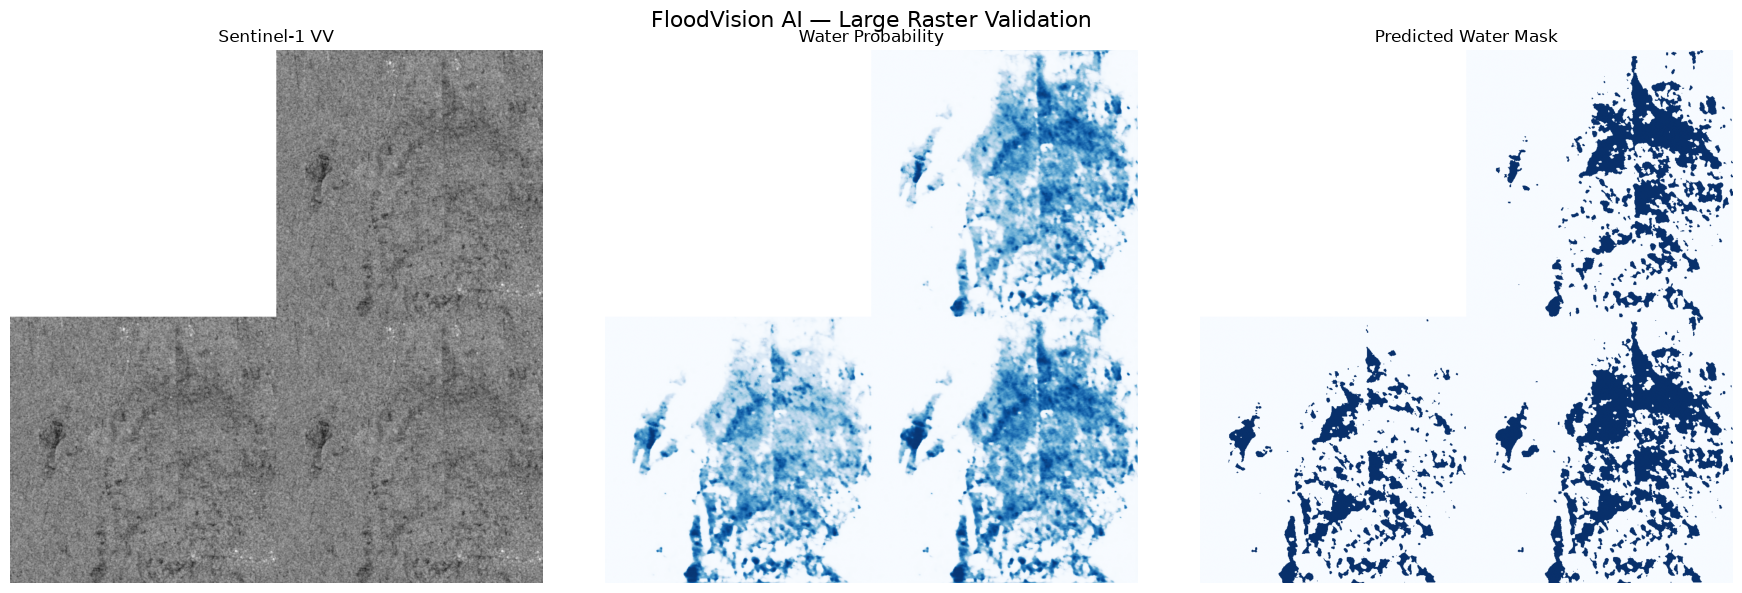

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

axes[0].imshow(
    large_image[0],
    cmap="gray"
)

axes[0].set_title("Sentinel-1 VV")

axes[1].imshow(
    large_probability,
    cmap="Blues",
    vmin=0,
    vmax=1
)

axes[1].set_title("Water Probability")

axes[2].imshow(
    np.ma.masked_equal(large_mask, -1),
    cmap="Blues",
    vmin=0,
    vmax=1
)

axes[2].set_title("Predicted Water Mask")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    "FloodVision AI — Large Raster Validation",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    VALIDATION_DIR /
    "large_raster_validation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [40]:
all_invalid_path = (
    TEST_DIR /
    f"all_invalid_{uuid.uuid4().hex[:8]}.tif"
)

with rasterio.open(sample_path) as src:
    invalid_profile = src.profile.copy()

invalid_image = np.full(
    (2, 512, 512),
    np.nan,
    dtype=np.float32
)

invalid_profile.update(
    driver="GTiff",
    dtype="float32",
    count=2,
    height=512,
    width=512,
    nodata=np.nan
)

with rasterio.open(
    all_invalid_path,
    "w",
    **invalid_profile
) as dst:

    dst.write(invalid_image)

    dst.set_band_description(1, "VV")
    dst.set_band_description(2, "VH")

assert all_invalid_path.is_file()

print("Shape:", invalid_image.shape)
print("Invalid pixels:", 512 * 512)

print("\nAll-invalid raster ready!")

Shape: (2, 512, 512)
Invalid pixels: 262144

All-invalid raster ready!


In [41]:
invalid_output_dir = (
    VALIDATION_DIR /
    f"invalid_analysis_{uuid.uuid4().hex[:12]}"
)

invalid_result = pipeline.predict(
    input_path=all_invalid_path,
    output_dir=invalid_output_dir,
    export_rasters=True,
    export_vectors=True,
    calculate_area=True
)

print(invalid_result.to_json())

print("\nAll-invalid inference completed!")

{
    "project": "FloodVision AI",
    "analysis_id": "2395466bbf9a45bcb3ae27ccd4d90511",
    "status": "completed",
    "task": "binary_water_segmentation",
    "deployment_status": "research_prototype",
    "source_file": "all_invalid_3e5d7906.tif",
    "model": {
        "version": "1.0.0",
        "device": "cpu",
        "threshold": 0.5
    },
    "geospatial_metadata": {
        "width": 512,
        "height": 512,
        "crs": "EPSG:4326",
        "crs_type": "geographic",
        "coordinate_unit": "degree",
        "bounds": {
            "left": 105.83160160046177,
            "bottom": 12.00436680474599,
            "right": 105.8775953430087,
            "top": 12.05036054729291
        },
        "resolution": {
            "x": 8.983152841195215e-05,
            "y": 8.983152841195215e-05,
            "unit": "degree"
        },
        "center": {
            "x": 105.85459847173523,
            "y": 12.02736367601945,
            "longitude": 105.85459847173523,
    

In [42]:
assert invalid_result.status == "completed"

assert invalid_result.statistics[
    "total_pixels"
] == 262144

assert invalid_result.statistics[
    "valid_pixels"
] == 0

assert invalid_result.statistics[
    "invalid_pixels"
] == 262144

assert invalid_result.statistics[
    "water_pixels"
] == 0

assert invalid_result.statistics[
    "non_water_pixels"
] == 0

assert invalid_result.water_coverage is None

assert invalid_result.water_area_km2 == 0

assert invalid_result.tiling[
    "processed_tiles"
] == 0

assert invalid_result.tiling[
    "skipped_tiles"
] == 1

assert invalid_result.vectorization[
    "region_count"
] == 0

assert invalid_result.warnings

print("[PASS] No valid satellite data")
print("[PASS] No false water predictions")
print("[PASS] Undefined water coverage")
print("[PASS] Zero predicted water area")
print("[PASS] Model inference skipped")
print("[PASS] Empty vector regions")
print("[PASS] Warning generated")

print("\nAll-invalid pipeline validation PASSED!")

[PASS] No valid satellite data
[PASS] No false water predictions
[PASS] Undefined water coverage
[PASS] Zero predicted water area
[PASS] Model inference skipped
[PASS] Empty vector regions
[PASS] Warning generated

All-invalid pipeline validation PASSED!


In [43]:
with rasterio.open(
    invalid_result.get_artifact_path("water_mask")
) as src:

    invalid_mask = src.read(1)

with rasterio.open(
    invalid_result.get_artifact_path(
        "water_probability"
    )
) as src:

    invalid_probability = src.read(1)

assert np.all(invalid_mask == -1)

assert np.isnan(invalid_probability).all()

with open(
    invalid_result.get_artifact_path(
        "water_regions_original"
    ),
    encoding="utf-8"
) as file:

    empty_geojson = json.load(file)

assert empty_geojson["type"] == "FeatureCollection"

assert empty_geojson["features"] == []

print("[PASS] All-invalid mask")
print("[PASS] All-invalid probability raster")
print("[PASS] Empty GeoJSON")
print("[PASS] No fabricated water regions")

print("\nEmpty artifact validation PASSED!")

[PASS] All-invalid mask
[PASS] All-invalid probability raster
[PASS] Empty GeoJSON
[PASS] No fabricated water regions

Empty artifact validation PASSED!


In [48]:
from unittest.mock import patch

from floodvision.inference.geometry_fidelity import (
    GeometryFidelityValidator
)

validators = [
    (name, value)
    for name, value in vars(pipeline).items()
    if isinstance(value, GeometryFidelityValidator)
]

assert len(validators) == 1, (
    "Expected exactly one geometry fidelity validator."
)

validator_name, fidelity_validator = validators[0]

print("Validator attribute:", validator_name)

original_validate = fidelity_validator.validate

validation_calls = []

def forced_fidelity_failure(*args, **kwargs):

    fidelity = original_validate(
        *args,
        **kwargs
    )

    validation_calls.append(fidelity.copy())

    # Reject simplified geometry only
    if len(validation_calls) == 2:

        fidelity = fidelity.copy()

        fidelity["passed"] = False
        fidelity["geometry_iou"] = 0.95
        fidelity["changed_pixels"] = 100

    return fidelity

print("[PASS] Geometry validator located")
print("[PASS] Failure simulation configured")

print("\nForced fallback test ready!")

Validator attribute: fidelity_validator
[PASS] Geometry validator located
[PASS] Failure simulation configured

Forced fallback test ready!


In [49]:
validation_calls.clear()

fallback_output_dir = (
    VALIDATION_DIR /
    f"fallback_analysis_{uuid.uuid4().hex[:12]}"
)

with patch.object(
    fidelity_validator,
    "validate",
    side_effect=forced_fidelity_failure
):

    fallback_result = pipeline.predict(
        input_path=sample_path,
        output_dir=fallback_output_dir,
        export_rasters=True,
        export_vectors=True,
        calculate_area=True
    )

print(
    json.dumps(
        fallback_result.geometry_fidelity,
        indent=4
    )
)

print("\nWarnings:")

for warning in fallback_result.warnings:
    print(warning)

{
    "original": {
        "passed": true,
        "geometry_iou": 1.0,
        "changed_pixels": 0,
        "invalid_pixel_encroachment": 0,
        "overlap_area_m2": 0.0,
        "original_water_pixels": 66106,
        "reconstructed_water_pixels": 66106
    },
    "simplified": {
        "passed": false,
        "geometry_iou": 0.95,
        "changed_pixels": 100,
        "invalid_pixel_encroachment": 0,
        "overlap_area_m2": 5.587935447692871e-09,
        "original_water_pixels": 66106,
        "reconstructed_water_pixels": 66106
    },
    "fallback_used": true,
    "selected_variant": "original"
}

Warnings:
Simplified geometry failed fidelity validation. Original geometry retained.


In [50]:
assert len(validation_calls) == 2

assert fallback_result.status == "completed"

assert fallback_result.geometry_fidelity[
    "original"
]["passed"]

assert not fallback_result.geometry_fidelity[
    "simplified"
]["passed"]

assert fallback_result.geometry_fidelity[
    "fallback_used"
]

assert fallback_result.geometry_fidelity[
    "selected_variant"
] == "original"

assert "water_regions_original" in (
    fallback_result.artifacts
)

assert "water_regions_simplified" not in (
    fallback_result.artifacts
)

assert len(fallback_result.artifacts) == 5

assert fallback_result.warnings

assert (
    fallback_result.statistics["water_pixels"]
    == pipeline_result.statistics["water_pixels"]
)

print("[PASS] Original geometry accepted")
print("[PASS] Simplified geometry rejected")
print("[PASS] Automatic fallback activated")
print("[PASS] Original geometry preserved")
print("[PASS] Unsafe geometry not exported")
print("[PASS] Warning generated")
print("[PASS] Prediction equivalence")

print("\nGeometry fallback protection PASSED!")

[PASS] Original geometry accepted
[PASS] Simplified geometry rejected
[PASS] Automatic fallback activated
[PASS] Original geometry preserved
[PASS] Unsafe geometry not exported
[PASS] Warning generated
[PASS] Prediction equivalence

Geometry fallback protection PASSED!


In [51]:
from floodvision.inference.exceptions import InferenceError

rejection_results = []

def expect_rejection(
    name,
    operation,
    expected_exception=InferenceError
):

    try:
        operation()

    except expected_exception as exc:

        rejection_results.append({
            "test": name,
            "passed": True,
            "exception": type(exc).__name__,
            "message": str(exc)
        })

        print(f"[PASS] {name}")
        print(f"       {type(exc).__name__}: {exc}")

    else:
        raise AssertionError(
            f"Expected rejection: {name}"
        )

print("Rejection testing utility ready!")

Rejection testing utility ready!


In [52]:
missing_input = (
    TEST_DIR /
    f"missing_{uuid.uuid4().hex}.tif"
)

missing_output = (
    VALIDATION_DIR /
    f"missing_test_{uuid.uuid4().hex[:8]}"
)

expect_rejection(
    "Missing satellite input",
    lambda: pipeline.predict(
        input_path=missing_input,
        output_dir=missing_output
    )
)

assert not missing_output.exists()

print("[PASS] No incomplete output created")

[PASS] Missing satellite input
       InputValidationError: Input raster not found: C:\Users\User\AppData\Local\Temp\floodvision_pipeline_s4r_5rif\missing_7012c7e355cb42fdb0f57d630d0a1441.tif
[PASS] No incomplete output created


In [53]:
unsupported_input = (
    TEST_DIR /
    f"unsupported_{uuid.uuid4().hex[:8]}.txt"
)

unsupported_input.write_text(
    "Not a satellite raster.",
    encoding="utf-8"
)

unsupported_output = (
    VALIDATION_DIR /
    f"unsupported_test_{uuid.uuid4().hex[:8]}"
)

expect_rejection(
    "Unsupported file format",
    lambda: pipeline.predict(
        input_path=unsupported_input,
        output_dir=unsupported_output
    )
)

assert not unsupported_output.exists()

print("[PASS] Unsupported input cleanup")

[PASS] Unsupported file format
       InputValidationError: Only .tif and .tiff files are supported.
[PASS] Unsupported input cleanup


In [54]:
wrong_band_path = (
    TEST_DIR /
    f"wrong_bands_{uuid.uuid4().hex[:8]}.tif"
)

with rasterio.open(sample_path) as src:

    wrong_band_profile = src.profile.copy()
    single_band = src.read(1)

wrong_band_profile.update(count=1)

with rasterio.open(
    wrong_band_path,
    "w",
    **wrong_band_profile
) as dst:

    dst.write(single_band, 1)
    dst.set_band_description(1, "VV")

wrong_band_output = (
    VALIDATION_DIR /
    f"wrong_band_test_{uuid.uuid4().hex[:8]}"
)

expect_rejection(
    "Incorrect SAR band count",
    lambda: pipeline.predict(
        input_path=wrong_band_path,
        output_dir=wrong_band_output
    )
)

assert not wrong_band_output.exists()

print("[PASS] Invalid band count cleanup")

[PASS] Incorrect SAR band count
       InputValidationError: Expected 2 channels, got 1.
[PASS] Invalid band count cleanup


In [55]:
existing_output = pipeline_result.output_dir

original_manifest_hash = (
    ArtifactManager.calculate_sha256(
        existing_output / "manifest.json"
    )
)

expect_rejection(
    "Existing output directory",
    lambda: pipeline.predict(
        input_path=sample_path,
        output_dir=existing_output
    )
)

current_manifest_hash = (
    ArtifactManager.calculate_sha256(
        existing_output / "manifest.json"
    )
)

assert (
    original_manifest_hash
    == current_manifest_hash
)

print("[PASS] Existing analysis preserved")
print("[PASS] Manifest unchanged")

[PASS] Existing output directory
       InferenceError: Output directory already exists: D:\FloodVision-AI\ml\artifacts\pipeline_validation\analysis_556b29a0812b
[PASS] Existing analysis preserved
[PASS] Manifest unchanged


In [56]:
from dataclasses import replace

limited_config = replace(
    config,
    max_pixels=500000,
    max_vector_pixels=500000
)

limited_pipeline = FloodInferencePipeline(
    bundle_dir=PRODUCTION_DIR,
    config=limited_config
)

limited_output = (
    VALIDATION_DIR /
    f"resource_test_{uuid.uuid4().hex[:8]}"
)

expect_rejection(
    "Maximum pixel limit exceeded",
    lambda: limited_pipeline.predict(
        input_path=large_raster_path,
        output_dir=limited_output
    )
)

assert not limited_output.exists()

print("[PASS] Resource limit enforced")
print("[PASS] No incomplete analysis")

[PASS] Maximum pixel limit exceeded
       PredictionError: Raster exceeds maximum supported pixel count.
[PASS] Resource limit enforced
[PASS] No incomplete analysis


In [57]:
tile_limited_config = replace(
    config,
    max_tiles=4
)

tile_limited_pipeline = FloodInferencePipeline(
    bundle_dir=PRODUCTION_DIR,
    config=tile_limited_config
)

tile_limited_output = (
    VALIDATION_DIR /
    f"tile_limit_test_{uuid.uuid4().hex[:8]}"
)

expect_rejection(
    "Maximum tile limit exceeded",
    lambda: tile_limited_pipeline.predict(
        input_path=large_raster_path,
        output_dir=tile_limited_output
    )
)

assert not tile_limited_output.exists()

print("[PASS] Tile limit enforced")
print("[PASS] Incomplete output prevented")

[PASS] Maximum tile limit exceeded
       PredictionError: Raster exceeds maximum supported tile count.
[PASS] Tile limit enforced
[PASS] Incomplete output prevented


In [58]:
from unittest.mock import patch

rollback_output = (
    VALIDATION_DIR /
    f"rollback_test_{uuid.uuid4().hex[:8]}"
)

staging_before = set(
    VALIDATION_DIR.glob(".floodvision_*")
)

with patch.object(
    pipeline,
    "_process_vectors",
    side_effect=RuntimeError(
        "Simulated vector processing failure"
    )
):

    expect_rejection(
        "Unexpected processing failure",
        lambda: pipeline.predict(
            input_path=sample_path,
            output_dir=rollback_output,
            export_rasters=True,
            export_vectors=True,
            calculate_area=True
        ),
        expected_exception=RuntimeError
    )

staging_after = set(
    VALIDATION_DIR.glob(".floodvision_*")
)

assert not rollback_output.exists()

assert staging_before == staging_after

print("[PASS] Incomplete output removed")
print("[PASS] Temporary staging cleaned")
print("[PASS] Automatic rollback successful")

[PASS] Unexpected processing failure
       RuntimeError: Simulated vector processing failure
[PASS] Incomplete output removed
[PASS] Temporary staging cleaned
[PASS] Automatic rollback successful


In [59]:
recovery_output = (
    VALIDATION_DIR /
    f"recovery_test_{uuid.uuid4().hex[:8]}"
)

recovery_result = pipeline.predict(
    input_path=sample_path,
    output_dir=recovery_output,
    export_rasters=False,
    export_vectors=False,
    calculate_area=False
)

assert recovery_result.status == "completed"

assert (
    recovery_result.statistics["water_pixels"]
    == pipeline_result.statistics["water_pixels"]
)

assert set(recovery_result.artifacts) == {
    "analysis_report",
    "manifest"
}

print("[PASS] Pipeline recovered after failure")
print("[PASS] Prediction consistency")
print("[PASS] Artifact generation")

print("\nPipeline recovery PASSED!")

[PASS] Pipeline recovered after failure
[PASS] Prediction consistency
[PASS] Artifact generation

Pipeline recovery PASSED!


In [60]:
import pandas as pd

rejection_df = pd.DataFrame(
    rejection_results
)

display(rejection_df)

assert len(rejection_df) == 7

assert rejection_df["passed"].all()

rejection_report_path = (
    VALIDATION_DIR /
    "pipeline_rejection_tests.csv"
)

rejection_df.to_csv(
    rejection_report_path,
    index=False
)

print("\nTotal rejection tests:", len(rejection_df))
print("Passed:", rejection_df["passed"].sum())
print("Failed:", (~rejection_df["passed"]).sum())

print("\nException protection validation PASSED!")

,test,passed,exception,message
0,Missing satellite input,True,InputValidationError,Input raster not found: C:\Users\User\AppData\...
1,Unsupported file format,True,InputValidationError,Only .tif and .tiff files are supported.
2,Incorrect SAR band count,True,InputValidationError,"Expected 2 channels, got 1."
3,Existing output directory,True,InferenceError,Output directory already exists: D:\FloodVisio...
4,Maximum pixel limit exceeded,True,PredictionError,Raster exceeds maximum supported pixel count.
5,Maximum tile limit exceeded,True,PredictionError,Raster exceeds maximum supported tile count.
6,Unexpected processing failure,True,RuntimeError,Simulated vector processing failure



Total rejection tests: 7
Passed: 7
Failed: 0

Exception protection validation PASSED!


In [61]:
audit_checks = {
    "Production model ready": (
        pipeline.get_model_info()["status"] == "ready"
    ),

    "Full pipeline completed": (
        pipeline_result.status == "completed"
    ),

    "Full artifact count": (
        len(pipeline_result.artifacts) == 6
    ),

    "Inference-only mode": (
        len(inference_only_result.artifacts) == 2
    ),

    "Raster-only mode": (
        len(raster_only_result.artifacts) == 4
    ),

    "Disk-backed mode": (
        disk_result.tiling["storage"] == "disk"
    ),

    "Storage mask equivalence": (
        np.array_equal(memory_mask, disk_mask)
    ),

    "Storage probability equivalence": (
        np.allclose(
            memory_probability,
            disk_probability,
            atol=1e-6,
            rtol=0,
            equal_nan=True
        )
    ),

    "Large raster integration": (
        large_result.statistics["total_pixels"]
        == 1048576
    ),

    "Large raster tile processing": (
        large_result.tiling["processed_tiles"] == 8
    ),

    "Invalid pixel preservation": (
        np.all(large_mask[:512, :512] == -1)
    ),

    "All-invalid handling": (
        invalid_result.statistics["valid_pixels"] == 0
        and invalid_result.water_coverage is None
        and invalid_result.tiling["processed_tiles"] == 0
    ),

    "Geometry fallback": (
        fallback_result.geometry_fidelity["fallback_used"]
        and "water_regions_simplified"
        not in fallback_result.artifacts
    ),

    "Exception protection": (
        len(rejection_df) == 7
        and rejection_df["passed"].all()
    ),

    "Pipeline recovery": (
        recovery_result.status == "completed"
        and recovery_result.statistics["water_pixels"]
        == pipeline_result.statistics["water_pixels"]
    )
}

print("=" * 65)
print("FLOODVISION AI — FINAL PIPELINE AUDIT")
print("=" * 65)

for name, passed in audit_checks.items():

    status = "PASS" if passed else "FAIL"

    print(f"[{status}] {name}")

passed_count = sum(
    bool(value)
    for value in audit_checks.values()
)

print("\nTotal checks:", len(audit_checks))
print("Passed:", passed_count)
print("Failed:", len(audit_checks) - passed_count)

assert all(audit_checks.values())

print("\nFINAL PIPELINE AUDIT PASSED!")

FLOODVISION AI — FINAL PIPELINE AUDIT
[PASS] Production model ready
[PASS] Full pipeline completed
[PASS] Full artifact count
[PASS] Inference-only mode
[PASS] Raster-only mode
[PASS] Disk-backed mode
[PASS] Storage mask equivalence
[PASS] Storage probability equivalence
[PASS] Large raster integration
[PASS] Large raster tile processing
[PASS] Invalid pixel preservation
[PASS] All-invalid handling
[PASS] Geometry fallback
[PASS] Exception protection
[PASS] Pipeline recovery

Total checks: 15
Passed: 15
Failed: 0

FINAL PIPELINE AUDIT PASSED!


In [62]:
from datetime import datetime, timezone

final_report = {
    "project": "FloodVision AI",
    "phase": "42 - Unified Inference Pipeline",
    "created_at": datetime.now(timezone.utc).isoformat(),

    "model": pipeline.get_model_info(),

    "audit": {
        "total_checks": len(audit_checks),
        "passed": passed_count,
        "failed": len(audit_checks) - passed_count,
        "checks": {
            name: bool(value)
            for name, value in audit_checks.items()
        }
    },

    "reference_sample": {
        "sample_id": sample_id,
        "statistics": pipeline_result.statistics,
        "area_analytics": pipeline_result.area_analytics,
        "geometry_fidelity": pipeline_result.geometry_fidelity,
        "timing": pipeline_result.timing
    },

    "large_raster_validation": {
        "synthetic_input": True,
        "statistics": large_result.statistics,
        "tiling": large_result.tiling,
        "area_analytics": large_result.area_analytics,
        "geometry_fidelity": large_result.geometry_fidelity,
        "timing": large_result.timing
    },

    "all_invalid_validation": {
        "statistics": invalid_result.statistics,
        "tiling": invalid_result.tiling,
        "warnings": invalid_result.warnings
    },

    "fallback_validation": {
        "simulated_failure": True,
        "geometry_fidelity": fallback_result.geometry_fidelity,
        "warnings": fallback_result.warnings
    },

    "exception_tests": {
        "total": len(rejection_df),
        "passed": int(rejection_df["passed"].sum())
    },

    "limitations": [
        "Research prototype, not an emergency warning system.",
        "Predicted water is not confirmed flood extent.",
        "Synthetic integration tests do not establish geographical accuracy.",
        "Single-run processing times are not formal benchmarks.",
        "Automated regression testing remains pending."
    ]
}

report_path = (
    VALIDATION_DIR /
    "unified_pipeline_validation_report.json"
)

with open(report_path, "w", encoding="utf-8") as file:

    json.dump(
        final_report,
        file,
        indent=4,
        allow_nan=False
    )

print("Saved:", report_path)
print("\nFinal validation report generated!")

Saved: D:\FloodVision-AI\ml\artifacts\pipeline_validation\unified_pipeline_validation_report.json

Final validation report generated!


In [63]:
required_validation_files = [
    "pipeline_mode_comparison.csv",
    "pipeline_rejection_tests.csv",
    "large_raster_validation.png",
    "unified_pipeline_validation_report.json"
]

for filename in required_validation_files:

    path = VALIDATION_DIR / filename

    assert path.is_file(), f"Missing: {filename}"
    assert path.stat().st_size > 0

    print(
        f"[PASS] {filename} | "
        f"{path.stat().st_size / 1024:.2f} KiB"
    )

print("\nAll validation artifacts ready!")

[PASS] pipeline_mode_comparison.csv | 0.40 KiB
[PASS] pipeline_rejection_tests.csv | 0.80 KiB
[PASS] large_raster_validation.png | 2447.23 KiB
[PASS] unified_pipeline_validation_report.json | 8.25 KiB

All validation artifacts ready!
